# E3 · Segunda arquitectura: ResNet18 congelada + cabeza lineal

**Pregunta del experimento:** ¿qué arquitectura ofrece mejor compromiso entre métricas y costo?

**Comparación primaria del taller: E1 frente a E3** (mismo régimen de extracción de características).
E3 es **idéntico a E1** salvo el backbone:

| | E1 | E3 |
|---|---|---|
| Backbone | MobileNetV2 (ImageNet) | **ResNet18 (ImageNet)** |
| Backbone congelado | Sí | Sí |
| Cabeza | 1 capa lineal 1280 → 5 | 1 capa lineal 512 → 5 |
| Épocas · LR · optimizador · batch · semilla | 10 · 0,001 · Adam · 32 · 42 | **iguales** |
| Datos, preprocesamiento, normalización | particiones finales · 256 + recorte 224 · ImageNet | **iguales** |
| Selección del modelo | mejor macro-F1 en validación | **igual** |

**No se compara E3 con E2** (difieren en arquitectura y en descongelamiento a la vez).

**Antes de ejecutar:** GPU T4 y acceso al secreto `GH_TOKEN` activados. Ejecutar las celdas **en orden y sin pausas largas**.

## Celda 1 · Configuración de la sesión
**Cambia tu nombre y el correo de tu cuenta de GitHub.**

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

token = userdata.get('GH_TOKEN')
![ -d /content/yuca_transfer ] || git clone https://{token}@github.com/Frank-Dev007/yuca_transfer.git /content/yuca_transfer
%cd /content/yuca_transfer
!git remote set-url origin https://{token}@github.com/Frank-Dev007/yuca_transfer.git
!git pull
!git config user.name "GhostnzaDevz64"
!git config user.email "tomasgonzalezlopez06@gmail.com"

!python scripts/preparar_datos.py
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
Cloning into '/content/yuca_transfer'...
remote: Enumerating objects: 216, done.
remote: Counting objects: 100% (216/216), done.
remote: Compressing objects: 100% (188/188), done.
remote: Total 216 (delta 101), reused 87 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (216/216), 20.94 MiB | 14.17 MiB/s, done.
Resolving deltas: 100% (101/101), done.
/content/yuca_transfer
Already up to date.
Copiando desde Drive...
Tamaño del zip (MB): 1354.1
Contenido de data/: ['cassavaleafdata', 'cassavaleafdata.zip']
name, memory.total [MiB]
Tesla T4, 15360 MiB


## Celda 2 · Verificar la configuración de E1 que hay que replicar
E3 debe usar **exactamente** la misma configuración que E1 y, para comparar tiempos, **la misma GPU**.
Si la GPU no coincide, anótenlo en la bitácora: los tiempos no serían directamente comparables.

In [2]:
import json, torch
m_e1 = json.load(open("results/E1/metricas.json"))
gpu_actual = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"E1 · épocas {m_e1['epocas']} | LR {m_e1['lr']} | batch {m_e1['batch_size']} | semilla {m_e1['semilla']} | "
      f"macro-F1 test {m_e1['test']['macro_f1']:.4f}")
print(f"GPU de E1: {m_e1['gpu']} | GPU actual: {gpu_actual} | "
      f"{'IGUAL' if m_e1['gpu'] == gpu_actual else 'DISTINTA: anotar en la bitácora'}")
assert m_e1["epocas"] == 10, "results/E1 no es E1 completo: revisar antes de seguir"

Exception ignored in: <function _WeakValueDictionary.__init__.<locals>.KeyedRef.remove at 0x7e9d0680cb80>
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 91, in remove
KeyboardInterrupt: 


E1 · épocas 10 | LR 0.001 | batch 32 | semilla 42 | macro-F1 test 0.6944
GPU de E1: Tesla T4 | GPU actual: Tesla T4 | IGUAL


## Celda 3 · Preparar
Mismos valores que E1: semilla 42, batch 32, LR 0,001, 10 épocas.
✅ Debe mostrar `cuda {'train': 5616, 'validation': 1878, 'test': 1874}`.

In [3]:
import importlib, os, sys
os.chdir("/content/yuca_transfer")
sys.path.append("/content/yuca_transfer")
importlib.invalidate_caches()

from src.utils import fijar_semilla, obtener_dispositivo
from src.data import crear_dataloaders
from src.models import crear_modelo
from src.train import ejecutar_experimento

SEED, BATCH, LR, EPOCAS = m_e1["semilla"], m_e1["batch_size"], m_e1["lr"], m_e1["epocas"]   # tomados de E1
fijar_semilla(SEED)
dispositivo = obtener_dispositivo()
loaders = crear_dataloaders(batch_size=BATCH, seed=SEED)
print(dispositivo, {s: len(l.dataset) for s, l in loaders.items()})
print(f"Configuración: semilla {SEED} | batch {BATCH} | LR {LR} | épocas {EPOCAS}")

cuda {'train': 5616, 'validation': 1878, 'test': 1874}
Configuración: semilla 42 | batch 32 | LR 0.001 | épocas 10


## Celda 4 · Crear ResNet18 congelada y comprobar qué se entrena
✅ Parámetros entrenables: **2.565** (512 × 5 pesos + 5 sesgos). Solo debe aparecer `fc` como entrenable.

In [4]:
fijar_semilla(SEED)
modelo = crear_modelo("resnet18")
entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
total = sum(p.numel() for p in modelo.parameters())
capas_entrenables = sorted({n.split(".")[0] for n, p in modelo.named_parameters() if p.requires_grad})
print(f"Parámetros entrenables: {entrenables:,} de {total:,} ({entrenables / total:.3%})")
print("Capas entrenables:", capas_entrenables)
print(f"Comparación: E1 (MobileNetV2) tenía {m_e1['parametros_entrenables']:,} entrenables de {m_e1['parametros_totales']:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


Parámetros entrenables: 2,565 de 11,179,077 (0.023%)
Capas entrenables: ['fc']
Comparación: E1 (MobileNetV2) tenía 6,405 entrenables de 2,230,277


## Celda 5 · Entrenar E3 (10 épocas) y registrar memoria de GPU
Usa la misma función `ejecutar_experimento` que E1 y E2. Además se mide la **memoria máxima de GPU** durante el entrenamiento.
Tarda aproximadamente lo mismo que E1 (unos 9 a 10 minutos).

Época  1 | pérdida train 0.9993 | pérdida val 0.8080 | macro-F1 val 0.5760 | 56 s
Época  2 | pérdida train 0.7555 | pérdida val 0.7650 | macro-F1 val 0.5340 | 108 s
Época  3 | pérdida train 0.6967 | pérdida val 0.7095 | macro-F1 val 0.6110 | 160 s
Época  4 | pérdida train 0.6666 | pérdida val 0.6819 | macro-F1 val 0.6613 | 211 s
Época  5 | pérdida train 0.6499 | pérdida val 0.6759 | macro-F1 val 0.6807 | 263 s
Época  6 | pérdida train 0.6299 | pérdida val 0.6679 | macro-F1 val 0.6682 | 314 s
Época  7 | pérdida train 0.6164 | pérdida val 0.6802 | macro-F1 val 0.6704 | 364 s
Época  8 | pérdida train 0.6088 | pérdida val 0.6765 | macro-F1 val 0.6653 | 416 s
Época  9 | pérdida train 0.6049 | pérdida val 0.6607 | macro-F1 val 0.6702 | 466 s
Época 10 | pérdida train 0.5927 | pérdida val 0.6738 | macro-F1 val 0.6828 | 518 s


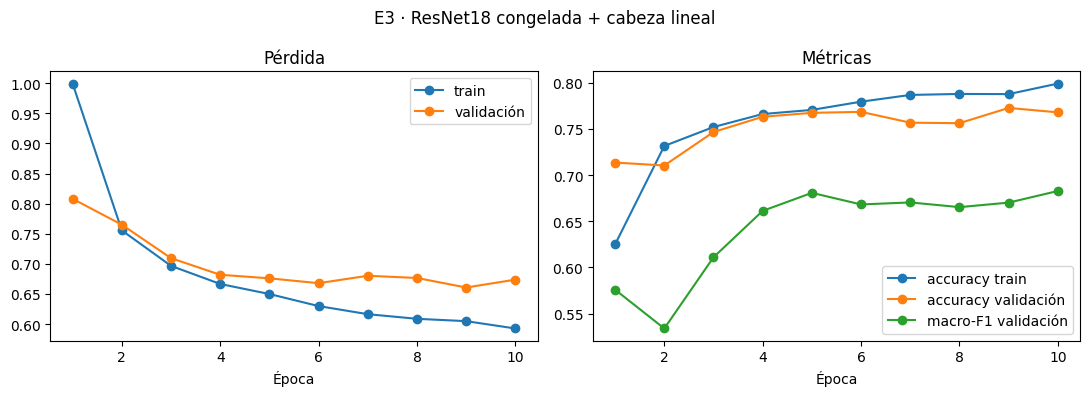

Validación (mejor época): accuracy = 0.7678 | macro-F1 = 0.6828
   cbb      recall = 0.417   F1 = 0.477   (n = 151)
   cbsd     recall = 0.683   F1 = 0.719   (n = 479)
   cgm      recall = 0.747   F1 = 0.698   (n = 257)
   cmd      recall = 0.889   F1 = 0.870   (n = 886)
   healthy  recall = 0.686   F1 = 0.649   (n = 105)

Test: accuracy = 0.7727 | macro-F1 = 0.6842
   cbb      recall = 0.357   F1 = 0.425   (n = 154)
   cbsd     recall = 0.713   F1 = 0.742   (n = 477)
   cgm      recall = 0.735   F1 = 0.674   (n = 253)
   cmd      recall = 0.892   F1 = 0.877   (n = 885)
   healthy  recall = 0.743   F1 = 0.703   (n = 105)


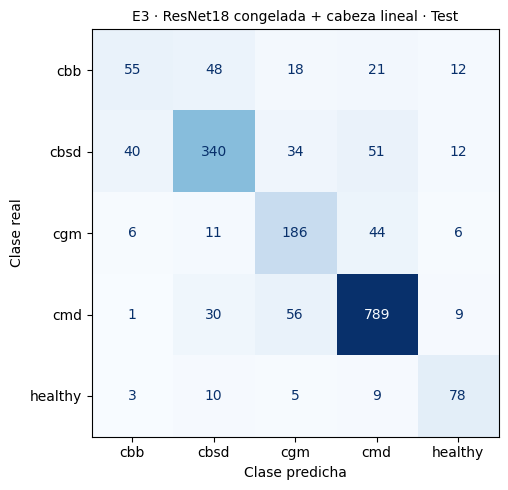


Mejor época: 10 | entrenamiento: 518 s | inferencia: 1.23 ms/imagen | parámetros entrenables: 2,565
Memoria máxima de GPU durante el entrenamiento: 287 MB


In [5]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

fijar_semilla(SEED)
r_e3 = ejecutar_experimento("E3", modelo, loaders, dispositivo, epocas=EPOCAS, lr=LR, semilla=SEED,
                            descripcion="ResNet18 congelada + cabeza lineal")

mem_entrenamiento_mb = torch.cuda.max_memory_allocated() / 1e6 if torch.cuda.is_available() else None
print(f"Memoria máxima de GPU durante el entrenamiento: {mem_entrenamiento_mb:.0f} MB")

## Celda 6 · Registro de recursos y configuración
Guarda en `results/E3/config_recursos.json` todo lo necesario para reproducir y comparar el costo:
versiones, hardware, configuración, tiempos, parámetros, tamaño del modelo y memoria.
También agrega la memoria al `metricas.json` de E3.

In [6]:
import platform, torchvision, sklearn
from src.utils import fijar_semilla

registro = {
    "experimento": "E3",
    "fecha": __import__("datetime").date.today().isoformat(),
    "hardware": {"gpu": gpu_actual, "gpu_igual_a_E1": m_e1["gpu"] == gpu_actual},
    "software": {"python": platform.python_version(), "torch": torch.__version__,
                 "torchvision": torchvision.__version__, "scikit-learn": sklearn.__version__},
    "configuracion": {"backbone": "resnet18 (IMAGENET1K_V1), congelado", "cabeza": "Linear(512, 5)",
                      "epocas": EPOCAS, "lr": LR, "optimizador": "Adam", "batch_size": BATCH, "semilla": SEED,
                      "preprocesamiento": "Resize(256) + CenterCrop(224) + normalización ImageNet",
                      "augmentation": "ninguno", "seleccion": "mejor macro-F1 en validación",
                      "particiones": "results/particiones_finales.csv"},
    "recursos": {"tiempo_entrenamiento_s": r_e3["tiempo_entrenamiento_s"],
                 "segundos_por_epoca": r_e3["tiempo_entrenamiento_s"] / EPOCAS,
                 "tiempo_inferencia_ms_por_imagen": r_e3["tiempo_inferencia_ms_por_imagen"],
                 "parametros_totales": r_e3["parametros_totales"],
                 "parametros_entrenables": r_e3["parametros_entrenables"],
                 "tamano_checkpoint_mb": r_e3["tamano_checkpoint_mb"],
                 "memoria_gpu_pico_entrenamiento_mb": mem_entrenamiento_mb},
}
json.dump(registro, open("results/E3/config_recursos.json", "w"), indent=2, ensure_ascii=False)

m_e3 = json.load(open("results/E3/metricas.json"))
m_e3["memoria_gpu_pico_entrenamiento_mb"] = mem_entrenamiento_mb
json.dump(m_e3, open("results/E3/metricas.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(registro, indent=2, ensure_ascii=False))

{
  "experimento": "E3",
  "fecha": "2026-11-19",
  "hardware": {
    "gpu": "Tesla T4",
    "gpu_igual_a_E1": true
  },
  "software": {
    "python": "3.13.16",
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "scikit-learn": "1.6.1"
  },
  "configuracion": {
    "backbone": "resnet18 (IMAGENET1K_V1), congelado",
    "cabeza": "Linear(512, 5)",
    "epocas": 10,
    "lr": 0.001,
    "optimizador": "Adam",
    "batch_size": 32,
    "semilla": 42,
    "preprocesamiento": "Resize(256) + CenterCrop(224) + normalización ImageNet",
    "augmentation": "ninguno",
    "seleccion": "mejor macro-F1 en validación",
    "particiones": "results/particiones_finales.csv"
  },
  "recursos": {
    "tiempo_entrenamiento_s": 518.197676897049,
    "segundos_por_epoca": 51.819767689704896,
    "tiempo_inferencia_ms_por_imagen": 1.2311317026615143,
    "parametros_totales": 11179077,
    "parametros_entrenables": 2565,
    "tamano_checkpoint_mb": 44.788363,
    "memoria_gpu_pico_entrenam

## Celda 7 · Medir E1 y E3 en las mismas condiciones (inferencia y memoria)
Para que el costo sea comparable, se cargan **los dos modelos guardados** y se miden aquí, en la misma GPU y sesión:
tiempo de inferencia por imagen, memoria máxima de GPU en inferencia y tamaño del archivo.

In [7]:
import time, pandas as pd

def medir_modelo(nombre_backbone, ruta_ckpt, n_lotes=30):
    m = crear_modelo(nombre_backbone)
    m.load_state_dict(torch.load(ruta_ckpt, map_location=dispositivo))
    m.to(dispositivo).eval()
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    total, n = 0.0, 0
    with torch.no_grad():
        for i, (x, _) in enumerate(loaders["test"]):
            x = x.to(dispositivo)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            t = time.time(); m(x)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            if i > 0:
                total += time.time() - t; n += len(x)
            if i >= n_lotes: break
    mem = torch.cuda.max_memory_allocated() / 1e6 if torch.cuda.is_available() else None
    del m
    return {"inferencia_ms_por_imagen": total / n * 1000, "memoria_gpu_inferencia_mb": mem,
            "tamano_archivo_mb": os.path.getsize(ruta_ckpt) / 1e6}

recursos = pd.DataFrame({"E1 (MobileNetV2)": medir_modelo("mobilenet_v2", "checkpoints/E1.pt"),
                         "E3 (ResNet18)": medir_modelo("resnet18", "checkpoints/E3.pt")}).T.round(3)
recursos.to_csv("results/E3/recursos_E1_E3_misma_sesion.csv")
display(recursos)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 135MB/s]


,inferencia_ms_por_imagen,memoria_gpu_inferencia_mb,tamano_archivo_mb
E1 (MobileNetV2),1.211,427.165,9.148
E3 (ResNet18),1.246,333.084,44.788


## Celda 8 · Comparación primaria E1 frente a E3 (hechos, sin interpretar)

,Experimento,Accuracy test,Macro-F1 test,Macro-F1 val,Mejor época,Entrenamiento (s),Parámetros totales,Parámetros entrenables,Checkpoint (MB)
0,E1 (MobileNetV2),0.7689,0.6944,0.7040,9,524.0918,2230277,6405,9.1479
1,E3 (ResNet18),0.7727,0.6842,0.6828,10,518.1977,11179077,2565,44.7884


Diferencia de macro-F1 (E3 - E1): -0.0103 (referencia: variación entre dos ejecuciones de E1 = 0,0078)

Por clase en test:


,recall E1,recall E3,F1 E1,F1 E3,dif. recall,dif. F1
cbb,0.539,0.357,0.476,0.425,-0.182,-0.051
cbsd,0.795,0.713,0.741,0.742,-0.082,0.001
cgm,0.723,0.735,0.725,0.674,0.012,-0.051
cmd,0.832,0.892,0.872,0.877,0.060,0.005
healthy,0.571,0.743,0.659,0.703,0.172,0.044


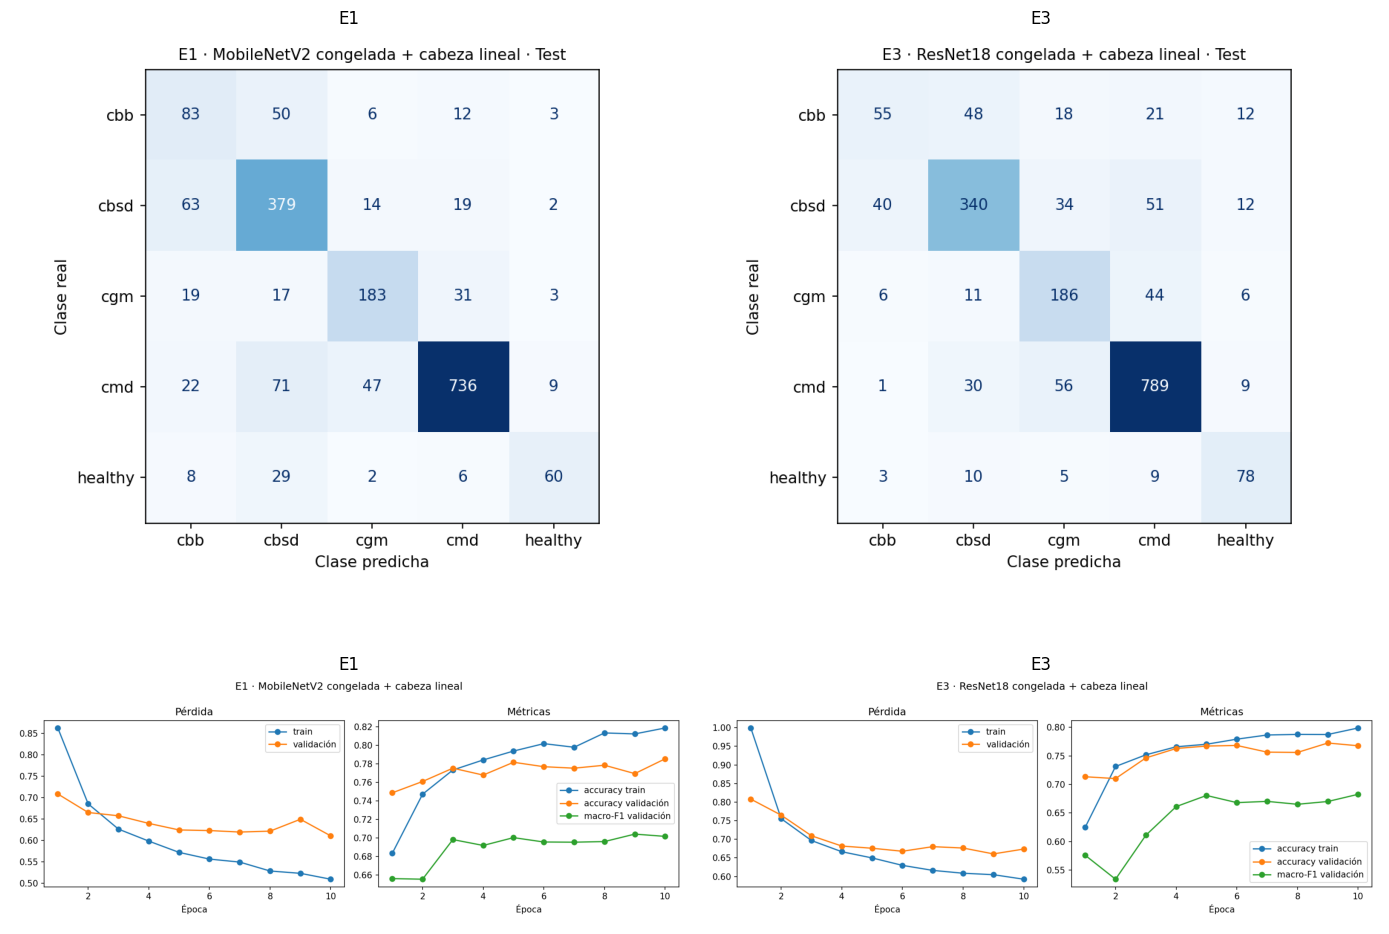

In [8]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage

m_e3 = json.load(open("results/E3/metricas.json"))
tabla = pd.DataFrame([
    {"Experimento": "E1 (MobileNetV2)", "Accuracy test": m_e1["test"]["accuracy"], "Macro-F1 test": m_e1["test"]["macro_f1"],
     "Macro-F1 val": m_e1["validacion"]["macro_f1"], "Mejor época": m_e1["mejor_epoca"],
     "Entrenamiento (s)": m_e1["tiempo_entrenamiento_s"], "Parámetros totales": m_e1["parametros_totales"],
     "Parámetros entrenables": m_e1["parametros_entrenables"], "Checkpoint (MB)": m_e1["tamano_checkpoint_mb"]},
    {"Experimento": "E3 (ResNet18)", "Accuracy test": m_e3["test"]["accuracy"], "Macro-F1 test": m_e3["test"]["macro_f1"],
     "Macro-F1 val": m_e3["validacion"]["macro_f1"], "Mejor época": m_e3["mejor_epoca"],
     "Entrenamiento (s)": m_e3["tiempo_entrenamiento_s"], "Parámetros totales": m_e3["parametros_totales"],
     "Parámetros entrenables": m_e3["parametros_entrenables"], "Checkpoint (MB)": m_e3["tamano_checkpoint_mb"]},
]).round(4)
tabla.to_csv("results/E3/comparacion_E1_E3.csv", index=False)
display(tabla)
print(f"Diferencia de macro-F1 (E3 - E1): {m_e3['test']['macro_f1'] - m_e1['test']['macro_f1']:+.4f} "
      f"(referencia: variación entre dos ejecuciones de E1 = 0,0078)")

por_clase = pd.DataFrame({
    "recall E1": {c: v["recall"] for c, v in m_e1["test"]["por_clase"].items()},
    "recall E3": {c: v["recall"] for c, v in m_e3["test"]["por_clase"].items()},
    "F1 E1": {c: v["f1"] for c, v in m_e1["test"]["por_clase"].items()},
    "F1 E3": {c: v["f1"] for c, v in m_e3["test"]["por_clase"].items()}}).round(3)
por_clase["dif. recall"] = (por_clase["recall E3"] - por_clase["recall E1"]).round(3)
por_clase["dif. F1"] = (por_clase["F1 E3"] - por_clase["F1 E1"]).round(3)
print("\nPor clase en test:"); display(por_clase)
por_clase.to_csv("results/E3/por_clase_E1_E3.csv")

fig, ejes = plt.subplots(2, 2, figsize=(14, 11))
for fila, archivo in enumerate(["matriz_confusion_test.png", "curvas.png"]):
    for col, exp in enumerate(["E1", "E3"]):
        ejes[fila, col].imshow(PILImage.open(f"results/{exp}/{archivo}"))
        ejes[fila, col].set_title(exp); ejes[fila, col].axis("off")
plt.tight_layout()
plt.savefig("results/E3/comparacion_visual_E1_E3.png", dpi=120)
plt.show()

## Celda 9 · Subir resultados

In [9]:
!git pull
!git add results/E3 checkpoints/E3.pt
!git commit -m "E3: ResNet18 congelada + cabeza lineal; registro de recursos y comparación con E1"
!git push

Already up to date.
[main cde8e56] E3: ResNet18 congelada + cabeza lineal; registro de recursos y comparación con E1
 11 files changed, 2023 insertions(+)
 create mode 100644 checkpoints/E3.pt
 create mode 100644 results/E3/comparacion_E1_E3.csv
 create mode 100644 results/E3/comparacion_visual_E1_E3.png
 create mode 100644 results/E3/config_recursos.json
 create mode 100644 results/E3/curvas.png
 create mode 100644 results/E3/historial.csv
 create mode 100644 results/E3/matriz_confusion_test.png
 create mode 100644 results/E3/metricas.json
 create mode 100644 results/E3/por_clase_E1_E3.csv
 create mode 100644 results/E3/predicciones_test.csv
 create mode 100644 results/E3/recursos_E1_E3_misma_sesion.csv
Enumerating objects: 19, done.
Counting objects: 100% (19/19), done.
Delta compression using up to 2 threads
Compressing objects: 100% (16/16), done.
Writing objects: 100% (16/16), 39.95 MiB | 9.70 MiB/s, done.
Total 16 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving del

## Celda 10 · Subir este notebook
1. Pulsa **Ctrl + S**.
2. Ejecuta `!ls "/content/drive/MyDrive/Colab Notebooks/"` y busca el nombre de este notebook.
3. Reemplaza `NOMBRE_EXACTO` por ese nombre (tal cual, entre las comillas). El nombre final no se cambia.

Antes: revisa que ninguna salida muestre `github_pat_` o `ghp_`.

In [ ]:
%cd /content/yuca_transfer
!cp "/content/drive/MyDrive/Colab Notebooks/NOMBRE_EXACTO.ipynb" notebooks/05_E3_resnet18.ipynb
!git add notebooks/05_E3_resnet18.ipynb
!git commit -m "Notebook E3"
!git push